In [1]:
! pip install pm4py
! pip install graphviz

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.7/2.7 MB 32.4 MB/s eta 0:00:00


In [2]:
import numpy as np
import pandas as pd
import pm4py

from pm4py.visualization.common import gview



  Welcome to PM4Py — Community Version
  Open-Source License (AGPL v3)

  📚 Docs & Examples:
     https://processintelligence.solutions/pm4py

  ⚖️  License: AGPL v3 — Commercial use requires open-sourcing your application.
     Business use without open-sourcing? A commercial license is available:
     https://processintelligence.solutions/pm4py#licensing




In [3]:
df_raw = pd.read_csv('flow00.csv')
df_raw.head()

,timestamp,scenario,log_type,message
0,"2026-09-22 20:34:53,186",test00,INFO,Logging to file: tmp/e0/log
1,"2026-09-22 20:34:53,189",test00,INFO,Prompting user for Python function description.
2,"2026-09-22 20:35:03,533",test00,INFO,User provided description : Create a function ...
3,"2026-09-22 20:35:03,533",test00,INFO,Generating code using LLM model : qwen3.6:35b-...
4,"2026-09-22 20:36:37,568",test00,INFO,HTTP Request: POST http://localhost:11434/v1/c...


In [4]:
# Filter out some of the unnecessary log entries
df = df_raw[df_raw['message'].isin([
    'Prompting user for Python function description.',
    'Generating code using LLM model : qwen3.6:35b-a3b-bf16',
    'Running generated code.',
    'Evaluating generated code.',
    # '',
])].copy()

# Clean up the text to make the model generated a little bit easier to read
df['state'] = ''
df.loc[df['message'] == 'Prompting user for Python function description.', 'state'] = 'prompt'
df.loc[df['message'] == 'Generating code using LLM model : qwen3.6:35b-a3b-bf16', 'state'] = 'inferring'
df.loc[df['message'] == 'Running generated code.', 'state'] = 'executing'
df.loc[df['message'] == 'Evaluating generated code.', 'state'] = 'evaluate'

# Drop the message column
df = df.drop(columns=['message'])

df.head()

,timestamp,scenario,log_type,state
1,"2026-09-22 20:34:53,189",test00,INFO,prompt
3,"2026-09-22 20:35:03,533",test00,INFO,inferring
7,"2026-09-22 20:36:37,572",test00,INFO,executing
9,"2026-09-22 20:36:37,583",test00,INFO,evaluate
13,"2026-09-22 20:38:37,286",test01,INFO,prompt


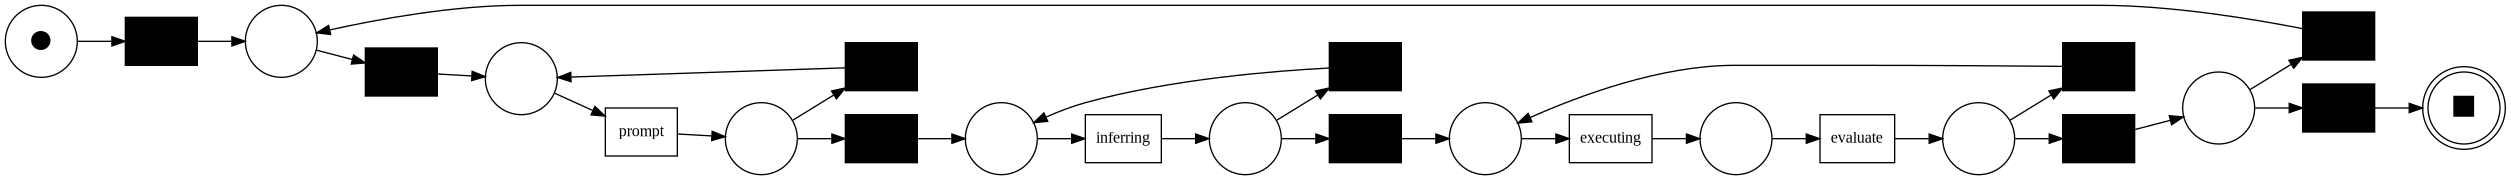

In [5]:
log = pm4py.format_dataframe(
    df,
    case_id='scenario',
    activity_key='state',
    timestamp_key='timestamp'
)

# Discover the Petri net (e.g., using Inductive Miner)
net, initial_marking, final_marking = pm4py.discover_petri_net_inductive(log)

# View the Petri net inside JupyterLab
pm4py.view_petri_net(net, initial_marking, final_marking)